# 08 · Figuras de resultados

Dibuja las siete figuras del capítulo de Resultados a partir de las tablas del notebook 07
(y, para el corte observado de 2024 de los nacimientos por clima educativo, del notebook 05).
No recalcula nada: correrlo sólo vuelve a dibujar.

| Figura (`resultados/figuras/`) | Título en la tesis |
|---|---|
| `fig_tgf_escenarios.png` | Tasa Global de Fecundidad proyectada, Escenario Base y Escenario Alternativo, 2026-2075 |
| `fig_piramide_evolucion_horizonte.png` | Estructura de la población por edad y sexo, 2010, 2025, 2050 y 2075 |
| `fig_tbn_tbm_historico_proyectado.png` | Tasa bruta de natalidad y tasa bruta de mortalidad, 2016-2075 |
| `fig_composicion_tramos_funcionales.png` | Composición de la población total por grupos de edad, 2026-2075 |
| `fig_matricula_por_tramo.png` | Matrícula proyectada por nivel del sistema educativo, Escenario Base |
| `fig_composicion_educativa_adultos_25_65.png` | Composición educativa de la población de 25 a 65 años, 2016-2075 |
| `fig_composicion_nacimientos_clima.png` | Composición de los nacimientos por clima educativo del hogar, 2010, 2024, 2050 y 2070 |

Las series proyectadas son la mediana de las 1.000 réplicas del Escenario Base; las bandas, el
intervalo entre los percentiles 2,5 y 97,5. En la figura de nacimientos por clima educativo,
2010 sale de la EAHU (niños de edad 0), 2024 de la EPH (nacimientos atribuidos a una madre,
notebook 05), y 2050 y 2070 de la simulación, medidos sobre los niños de 3 años del año t+3
(la mortalidad es la misma en todos los estratos).

**Tiempo aproximado:** 30 segundos.

In [1]:
import os
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(RAIZ)
DIR_RES = Path("resultados/tablas/resultados")
DIR_DESC = Path("resultados/tablas/descriptivas")
DIR_FIG = Path("resultados/figuras")
DIR_FIG.mkdir(parents=True, exist_ok=True)
ANIO_BASE = 2025

ESCALA_TEXTO = 1.2


def fs(pt):
    return round(pt * ESCALA_TEXTO * 2) / 2


FS_BASE, FS_TITULO, FS_EJE, FS_LEG, FS_ANOT, FS_PANEL = fs(15), fs(18), fs(16), fs(15), fs(13), fs(16)
ESTILO = {"figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "font.size": FS_BASE,
          "axes.titlesize": FS_TITULO, "axes.labelsize": FS_EJE, "xtick.labelsize": FS_BASE,
          "ytick.labelsize": FS_BASE, "legend.fontsize": FS_LEG, "figure.titlesize": FS_TITULO,
          "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.linestyle": ":",
          "grid.alpha": 0.4, "legend.frameon": False, "figure.autolayout": False}
C_PROPIO, C_ALT, C_REF = "#1B3A5C", "#C0392B", "#7F8C8D"
FMT_MILES = FuncFormatter(lambda x, _=None: f"{x:,.0f}".replace(",", "."))


def leyenda_afuera(ax, ncol=1, y=-0.16, fontsize=FS_LEG):
    return ax.legend(loc="upper center", bbox_to_anchor=(0.5, y), ncol=ncol, fontsize=fontsize,
                     frameon=False, borderaxespad=0.0)


def banda(ax, r, color, label, lw=2.0, alpha=0.18, ls="-"):
    ax.plot(r["year"], r["mediana"], color=color, lw=lw, label=label, zorder=3, linestyle=ls)
    if r["n_k"].max() > 1:
        ax.fill_between(r["year"], r["p025"], r["p975"], color=color, alpha=alpha, lw=0, zorder=2,
                        label="_nolegend_")

## TGF proyectada en los dos escenarios

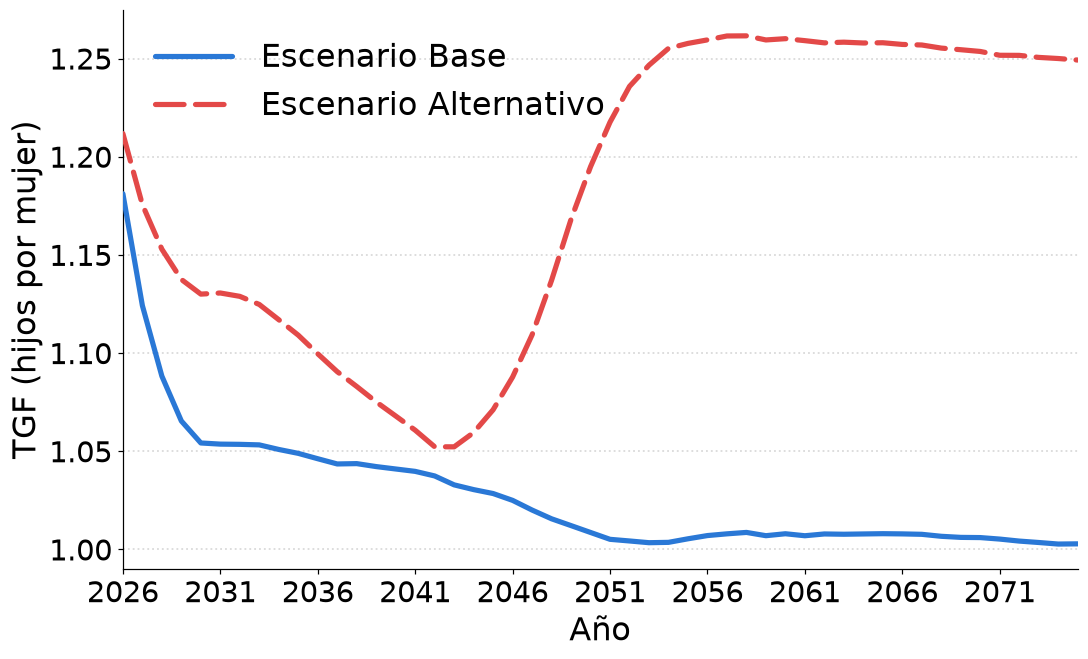

In [2]:
t = pd.read_csv(DIR_RES / "tgf_proyectada.csv")
FS_TICK, FS_LABEL, FS_LEG_TGF = 19, 21, 21
with plt.rc_context({"figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
                     "font.size": FS_TICK, "xtick.labelsize": FS_TICK, "ytick.labelsize": FS_TICK,
                     "axes.labelsize": FS_LABEL, "legend.fontsize": FS_LEG_TGF, "text.color": "#000000",
                     "axes.labelcolor": "#000000", "xtick.color": "#000000", "ytick.color": "#000000",
                     "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 300}):
    fig, ax = plt.subplots(figsize=(11.2, 6.6))
    ax.plot(t["year"], t["tgf_base"], color="#2a78d6", lw=3.4, solid_capstyle="round",
            label="Escenario Base", zorder=3)
    ax.plot(t["year"], t["tgf_rebote"], color="#e34948", lw=3.4, linestyle=(0, (5.5, 2.2)),
            dash_capstyle="round", label="Escenario Alternativo", zorder=3)
    ax.set_xlabel("Año")
    ax.set_ylabel("TGF (hijos por mujer)")
    ax.set_xlim(int(t.year.min()), int(t.year.max()))
    ax.set_xticks(range(int(t.year.min()), int(t.year.max()) + 1, 5))
    ax.grid(axis="y", color="#d7d7d7", linestyle=":", linewidth=1.2, alpha=0.9)
    ax.set_axisbelow(True)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
    for lado in ("left", "bottom"):
        ax.spines[lado].set_color("#000000")
    ax.legend(loc="upper left", borderaxespad=0.6, handlelength=2.4, handletextpad=0.9)
    fig.savefig(DIR_FIG / "fig_tgf_escenarios.png", bbox_inches="tight")
    plt.show()

## Pirámides de población (tramos quinquenales, % de la población total)

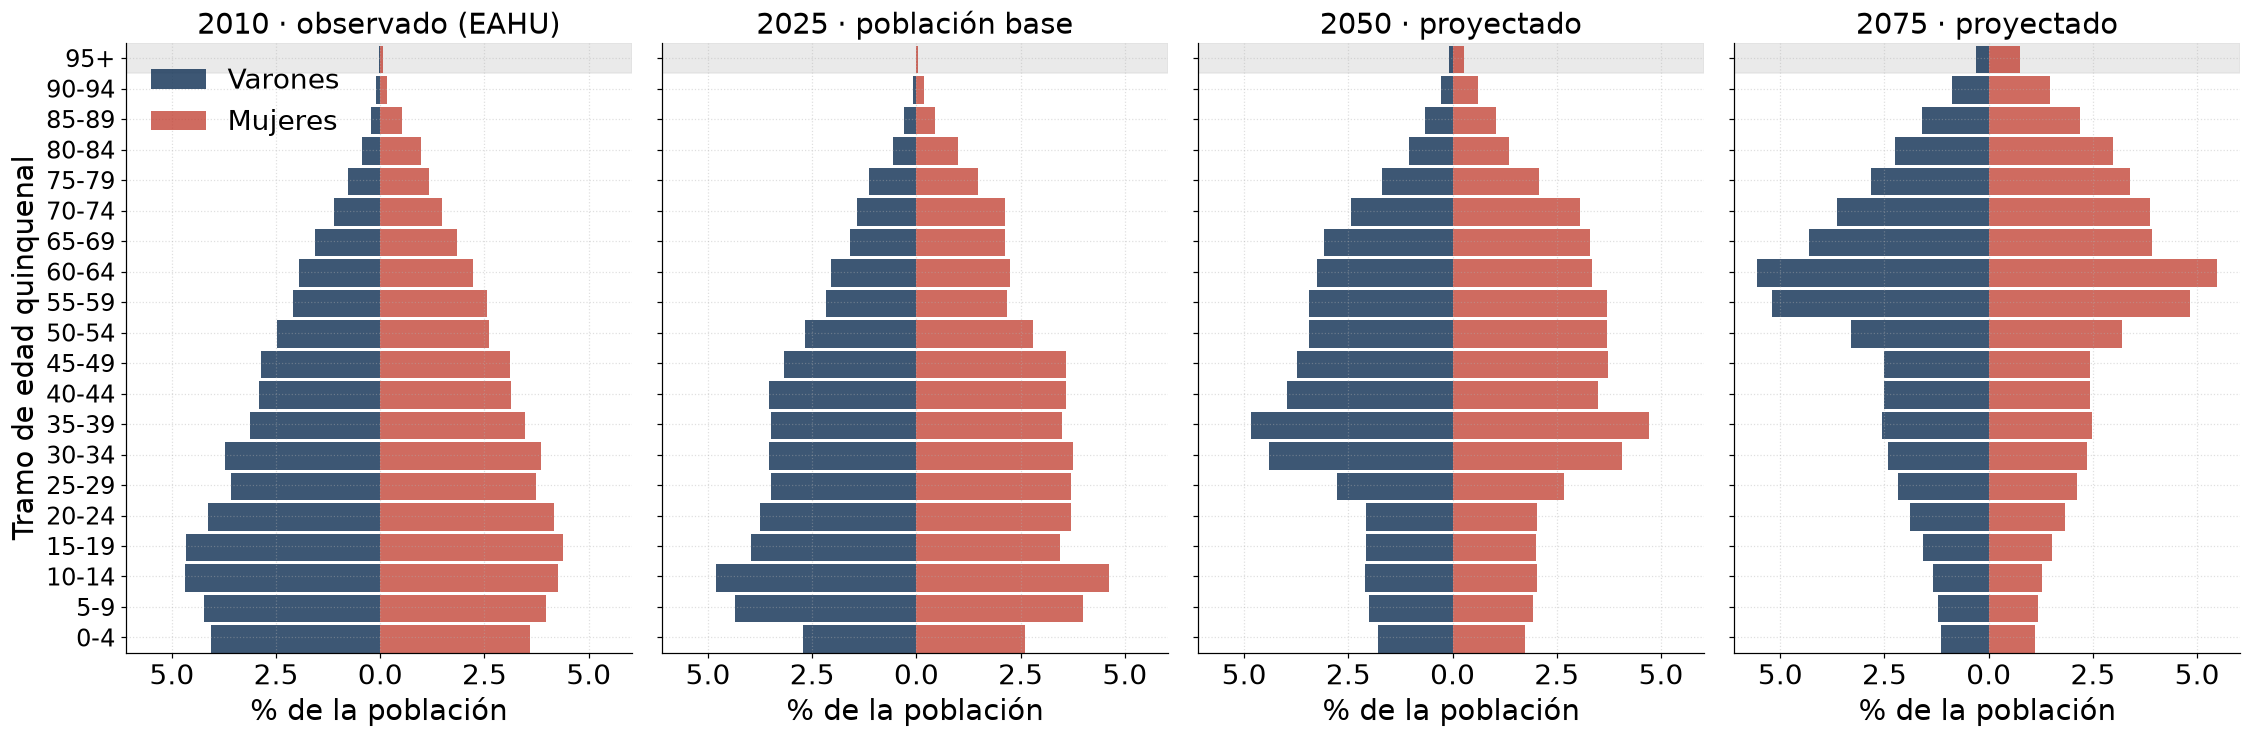

In [3]:
pir = pd.read_csv(DIR_RES / "piramides.csv")
EDAD_TRUNCAR, ANCHO = 95, 5
G5 = np.arange(0, EDAD_TRUNCAR + 1, ANCHO)
ET5 = [f"{g}-{g + ANCHO - 1}" for g in G5[:-1]] + [f"{G5[-1]}+"]


def piramide_pct(ax, d, titulo):
    e = d.copy()
    e["g5"] = (np.minimum(e["age"].to_numpy(), EDAD_TRUNCAR) // ANCHO) * ANCHO
    e = e.groupby(["sex", "g5"], as_index=False)["n"].sum()
    tot = e["n"].sum()
    v = e[e.sex == 0].set_index("g5")["n"].reindex(G5, fill_value=0) / tot * 100
    m = e[e.sex == 1].set_index("g5")["n"].reindex(G5, fill_value=0) / tot * 100
    ax.barh(G5, -v.values, height=ANCHO * 0.90, align="edge", color=C_PROPIO, alpha=0.85, label="Varones")
    ax.barh(G5, m.values, height=ANCHO * 0.90, align="edge", color=C_ALT, alpha=0.75, label="Mujeres")
    ax.axhspan(EDAD_TRUNCAR, EDAD_TRUNCAR + ANCHO, color="#DDDDDD", alpha=0.6, zorder=0)
    ax.set_yticks(G5 + ANCHO / 2.0)
    ax.set_yticklabels(ET5, fontsize=FS_ANOT)
    ax.set_ylim(0, EDAD_TRUNCAR + ANCHO)
    ax.set_title(titulo, fontsize=FS_PANEL)
    ax.set_xlabel("% de la población")
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{abs(x):,.1f}"))


with plt.rc_context(ESTILO):
    paneles = list(dict.fromkeys(pir["panel"]))
    fig, axes = plt.subplots(1, len(paneles), figsize=(6.2 * len(paneles), 7.2), sharey=True, sharex=True,
                             gridspec_kw={"wspace": 0.06})
    for ax, panel in zip(axes, paneles):
        piramide_pct(ax, pir[pir["panel"] == panel], panel)
    axes[0].set_ylabel("Tramo de edad quinquenal")
    axes[0].legend(loc="upper left", fontsize=FS_LEG)
    fig.savefig(DIR_FIG / "fig_piramide_evolucion_horizonte.png")
    plt.show()

## Tasa bruta de natalidad (observada y proyectada) y tasa bruta de mortalidad

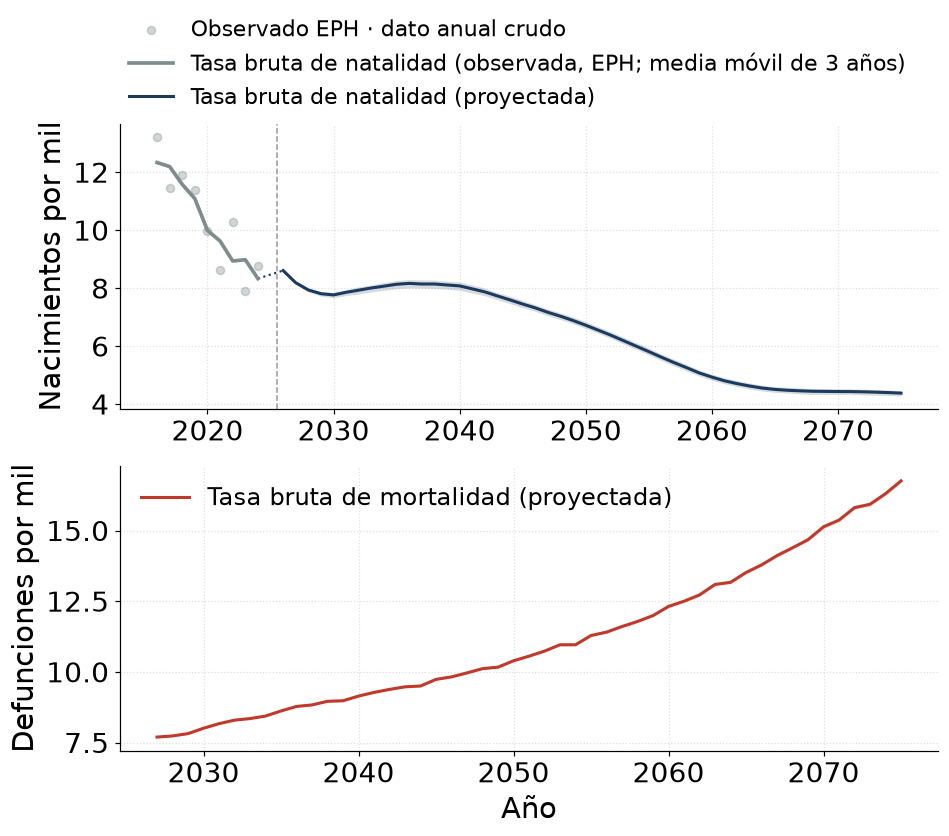

In [4]:
tbn_hist = pd.read_csv(DIR_RES / "tbn_observada.csv")
vit = pd.read_csv(DIR_RES / "natalidad_mortalidad_base.csv")
r_tbn = vit[["year", "tbn_mediana", "tbn_p025", "tbn_p975", "tbn_n_k"]].set_axis(
    ["year", "mediana", "p025", "p975", "n_k"], axis=1)
r_tbm = vit[["year", "tbm_mediana", "tbm_p025", "tbm_p975", "tbm_n_k"]].dropna().set_axis(
    ["year", "mediana", "p025", "p975", "n_k"], axis=1)

with plt.rc_context(ESTILO):
    fig, (axA, axB) = plt.subplots(2, 1, figsize=(9.6, 7.4), sharex=False)
    axA.scatter(tbn_hist["year"], tbn_hist["tbn"], s=28, color=C_REF, alpha=0.35, zorder=3,
                label="Observado EPH · dato anual crudo")
    axA.plot(tbn_hist["year"], tbn_hist["tbn_suave_mm3"], color=C_REF, lw=2.4, zorder=4,
             label="Tasa bruta de natalidad (observada, EPH; media móvil de 3 años)")
    axA.plot([tbn_hist["year"].iloc[-1], r_tbn["year"].iloc[0]],
             [tbn_hist["tbn_suave_mm3"].iloc[-1], r_tbn["mediana"].iloc[0]], color=C_PROPIO, lw=1.4, ls=":")
    banda(axA, r_tbn, C_PROPIO, "Tasa bruta de natalidad (proyectada)")
    axA.axvline(2025.5, color="#999999", lw=1.0, ls="--")
    axA.set_ylabel("Nacimientos por mil")
    axA.legend(loc="lower left", bbox_to_anchor=(0.0, 1.02), fontsize=fs(12), borderaxespad=0.0)
    banda(axB, r_tbm, C_ALT, "Tasa bruta de mortalidad (proyectada)")
    axB.set_ylabel("Defunciones por mil")
    axB.set_xlabel("Año")
    axB.legend(loc="upper left", fontsize=fs(13))
    fig.savefig(DIR_FIG / "fig_tbn_tbm_historico_proyectado.png")
    plt.show()

## Composición de la población por grupos de edad

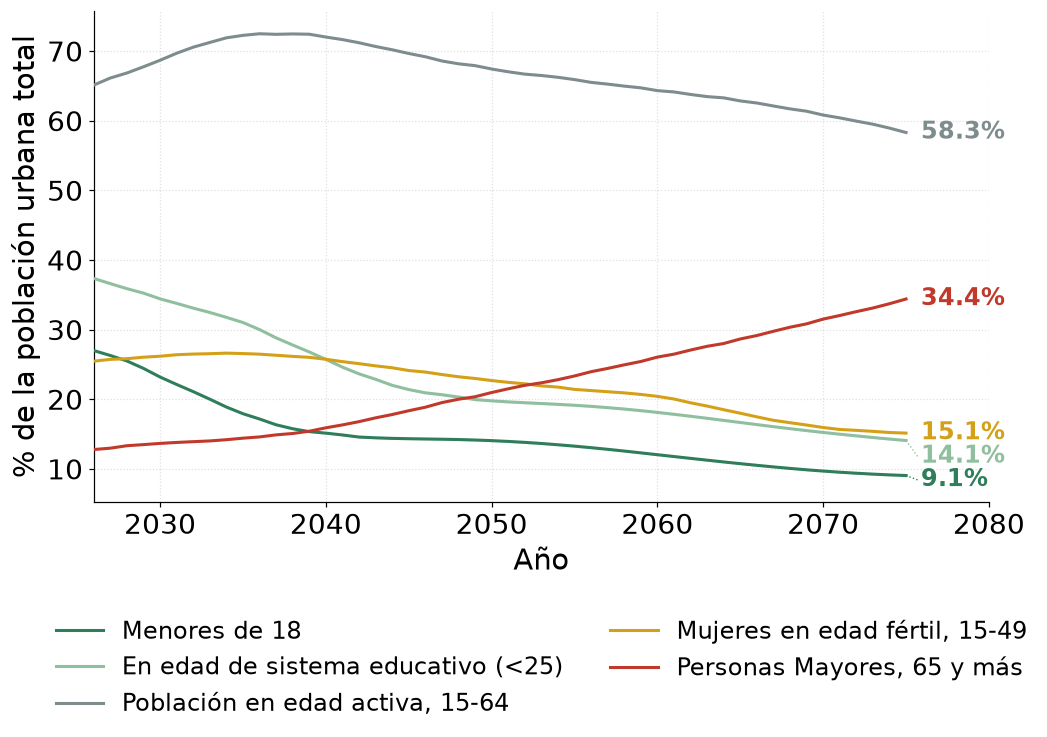

In [5]:
tramos = pd.read_csv(DIR_RES / "tramos_funcionales_base.csv")
COLORES_TRAMOS = {"Menores de 18": "#2E7D5B", "En edad de sistema educativo (<25)": "#8FBF9F",
                  "Población en edad activa, 15-64": C_REF, "Mujeres en edad fértil, 15-49": "#D4A017",
                  "Personas Mayores, 65 y más": C_ALT}

with plt.rc_context(ESTILO):
    fig, ax = plt.subplots(figsize=(10.5, 5.8))
    for etiqueta, color in COLORES_TRAMOS.items():
        banda(ax, tramos[tramos["tramo"] == etiqueta], color, etiqueta)
    finales = sorted(((float(tramos.loc[tramos["tramo"] == e, "mediana"].iloc[-1]), e) for e in COLORES_TRAMOS),
                     reverse=True)
    ys = [v for v, _ in finales]
    for i in range(1, len(ys)):
        ys[i] = min(ys[i], ys[i - 1] - 2.8 * ESCALA_TEXTO)
    x_fin = float(tramos["year"].max())
    for (valor, etiqueta), y_txt in zip(finales, ys):
        if abs(y_txt - valor) > 0.05:
            ax.plot([x_fin, x_fin + 0.7], [valor, y_txt], color=COLORES_TRAMOS[etiqueta], lw=0.9, ls=":",
                    clip_on=False, zorder=4)
        ax.text(x_fin + 0.9, y_txt, f"{valor:.1f}%", va="center", ha="left", fontsize=fs(13), fontweight="bold",
                color=COLORES_TRAMOS[etiqueta], clip_on=False, zorder=5)
    ax.set_xlim(tramos["year"].min(), tramos["year"].max() + 5)
    ax.set_xlabel("Año")
    ax.set_ylabel("% de la población urbana total")
    leyenda_afuera(ax, ncol=2, y=-0.22, fontsize=fs(13))
    fig.savefig(DIR_FIG / "fig_composicion_tramos_funcionales.png")
    plt.show()

## Matrícula proyectada por nivel del sistema educativo

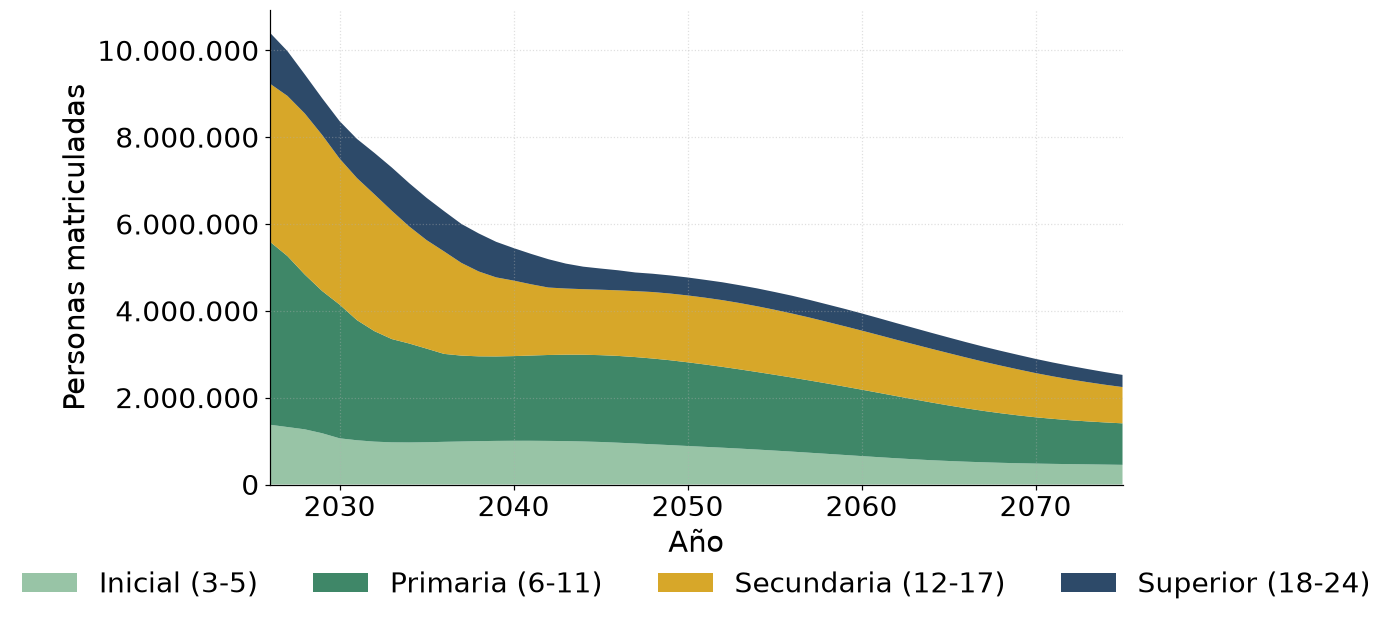

In [6]:
matricula = pd.read_csv(DIR_RES / "matricula_base.csv")
C_TRAMO = {"Inicial (3-5)": "#8FBF9F", "Primaria (6-11)": "#2E7D5B", "Secundaria (12-17)": "#D4A017",
           "Superior (18-24)": "#1B3A5C"}
piv = matricula.pivot(index="year", columns="tramo", values="mediana").reindex(columns=list(C_TRAMO))

with plt.rc_context(ESTILO):
    fig, ax = plt.subplots(figsize=(10, 5.6))
    ax.stackplot(piv.index, *[piv[c] for c in piv.columns], labels=list(piv.columns),
                 colors=[C_TRAMO[c] for c in piv.columns], alpha=0.92)
    ax.yaxis.set_major_formatter(FMT_MILES)
    ax.set_xlim(piv.index.min(), piv.index.max())
    ax.set_xlabel("Año")
    ax.set_ylabel("Personas matriculadas")
    leyenda_afuera(ax, ncol=4, y=-0.16)
    fig.savefig(DIR_FIG / "fig_matricula_por_tramo.png")
    plt.show()

## Composición educativa de la población de 25 a 65 años (siete niveles)

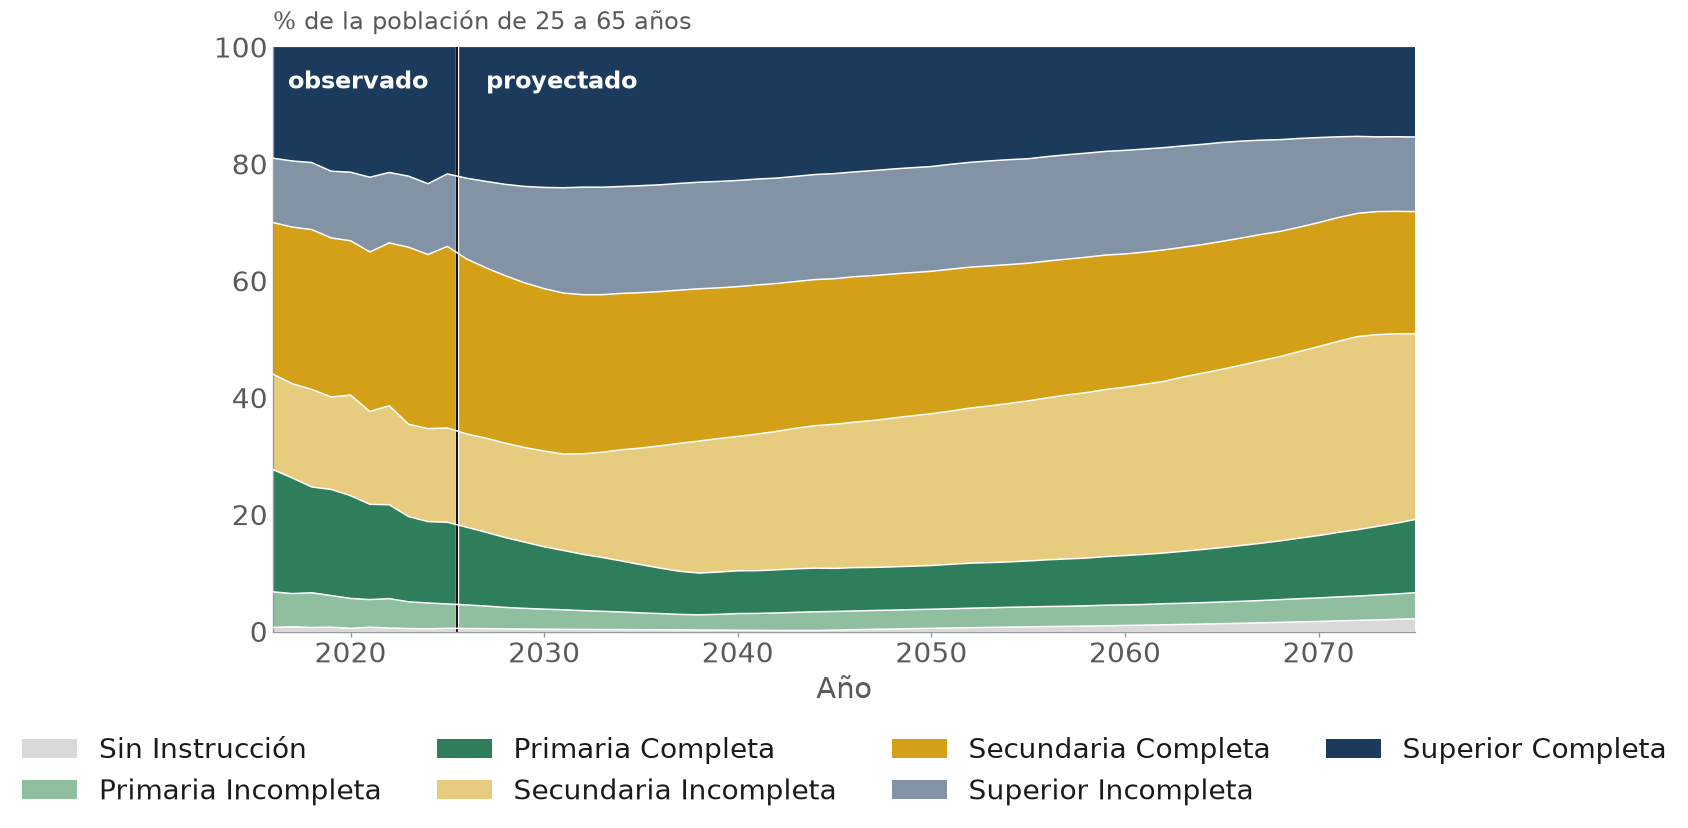

In [7]:
comp = pd.read_csv(DIR_RES / "composicion_educativa_25_65_base.csv").set_index("year").drop(columns="tramo")
ETIQUETAS = {"0 · Sin instrucción": ("Sin Instrucción", "#D9D9D9"),
             "1 · Primaria incompleta": ("Primaria Incompleta", "#8FBF9F"),
             "2 · Primaria completa": ("Primaria Completa", "#2E7D5B"),
             "3 · Secundaria incompleta": ("Secundaria Incompleta", None),
             "4 · Secundaria completa": ("Secundaria Completa", "#D4A017"),
             "5 · Superior incompleta": ("Superior Incompleta", None),
             "6 · Superior completa": ("Superior Completa", "#1B3A5C")}


def tinte(color_hex, hacia_blanco=0.45):
    r, g, b = mpl.colors.to_rgb(color_hex)
    return mpl.colors.to_hex((r + (1 - r) * hacia_blanco, g + (1 - g) * hacia_blanco, b + (1 - b) * hacia_blanco))


colores = {c: col for c, (_, col) in ETIQUETAS.items()}
colores["3 · Secundaria incompleta"] = tinte("#D4A017")
colores["5 · Superior incompleta"] = tinte("#1B3A5C")
C_TXT_SUAVE, C_EJE, C_GRID = "#5A5A5A", "#9A9A9A", "#CFCFCF"
ESTILO_DESAGREGADO = {
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "figure.facecolor": "white",
    "axes.facecolor": "white", "savefig.facecolor": "white", "font.size": FS_BASE, "axes.titlesize": FS_TITULO,
    "axes.labelsize": FS_EJE, "xtick.labelsize": FS_BASE, "ytick.labelsize": FS_BASE, "legend.fontsize": FS_LEG,
    "figure.titlesize": FS_TITULO, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": C_EJE,
    "axes.linewidth": 0.9, "axes.labelcolor": C_TXT_SUAVE, "text.color": "#1A1A1A", "xtick.color": C_EJE,
    "ytick.color": C_EJE, "xtick.labelcolor": C_TXT_SUAVE, "ytick.labelcolor": C_TXT_SUAVE,
    "xtick.major.size": 3.0, "xtick.major.width": 0.9, "ytick.major.size": 0.0, "axes.axisbelow": True,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": C_GRID, "grid.linestyle": "-",
    "grid.linewidth": 0.7, "grid.alpha": 0.30, "legend.frameon": False, "figure.autolayout": False}

with plt.rc_context(ESTILO_DESAGREGADO):
    fig, ax = plt.subplots(figsize=(13.4, 6.9))
    ax.stackplot(comp.index, *[comp[c].values for c in comp.columns], colors=[colores[c] for c in comp.columns],
                 labels=[ETIQUETAS[c][0] for c in comp.columns])
    acum = comp.cumsum(axis=1)
    for c in comp.columns[:-1]:
        ax.plot(comp.index, acum[c], color="white", lw=1.0, zorder=5)
    for lado in ("left", "bottom"):
        ax.spines[lado].set_color(C_EJE)
        ax.spines[lado].set_linewidth(0.9)
    ax.set_facecolor("white")
    ax.set_axisbelow(True)
    ax.grid(False)
    ax.set_ylim(0, 100)
    ax.set_xlim(comp.index.min(), comp.index.max())
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=4, fontsize=FS_LEG, frameon=False,
              borderaxespad=0.0)
    ax.axvline(ANIO_BASE + 0.5, color="w", lw=2.2)
    ax.axvline(ANIO_BASE + 0.5, color="k", lw=1.2)
    ax.text(ANIO_BASE - 1.0, 96, "observado", ha="right", va="top", color="white", fontsize=FS_ANOT,
            fontweight="bold")
    ax.text(ANIO_BASE + 2.0, 96, "proyectado", ha="left", va="top", color="white", fontsize=FS_ANOT,
            fontweight="bold")
    ax.set_xlabel("Año")
    ax.set_ylabel("")
    ax.annotate("% de la población de 25 a 65 años", xy=(0.0, 1.0), xycoords="axes fraction", xytext=(0, 8),
                textcoords="offset points", ha="left", va="bottom", fontsize=FS_ANOT, color=C_TXT_SUAVE)
    fig.savefig(DIR_FIG / "fig_composicion_educativa_adultos_25_65.png")
    plt.show()

## Composición de los nacimientos por clima educativo del hogar

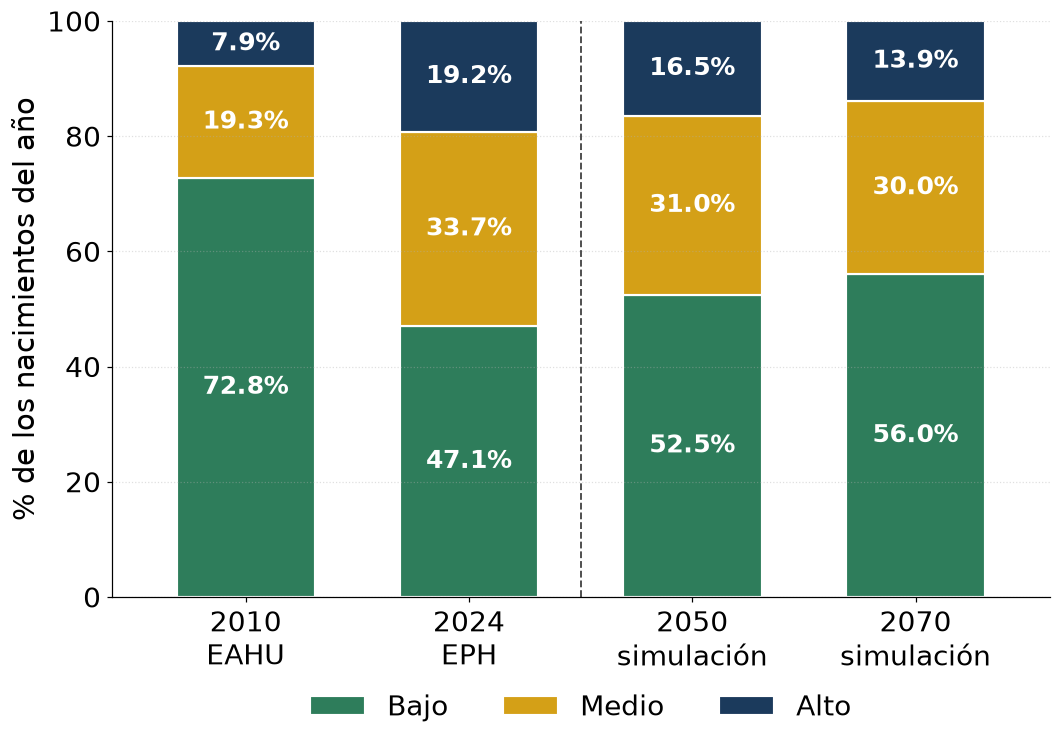

In [8]:
ORDEN_CLIMA = ["Bajo", "Medio", "Alto"]
C_CLIMA = {"Bajo": "#2E7D5B", "Medio": "#D4A017", "Alto": "#1B3A5C"}
w2010 = pd.read_csv(DIR_RES / "nacimientos_clima_2010.csv").set_index("clima3")["share_nacimientos_pct"]
t8 = pd.read_csv(DIR_DESC / "tabla8_recomposicion_clima_serie.csv")
t8 = t8[t8["year"] == 2024].copy()
t8["clima3"] = t8["clima_educativo"].str.extract(r"Clima (\w+)")[0].str.capitalize()
w2024 = t8.set_index("clima3")["share_nacimientos_pct"].reindex(ORDEN_CLIMA)
nc = pd.read_csv(DIR_RES / "nacimientos_clima.csv")
base = nc[nc["escenario"] == "base"].pivot(index="anio_nacimiento", columns="clima3", values="mediana")
base = base.div(base.sum(axis=1), axis=0) * 100
fotos = [(2010, w2010.reindex(ORDEN_CLIMA), "EAHU"), (2024, w2024, "EPH")]
fotos += [(a, base.loc[a].reindex(ORDEN_CLIMA), "simulación") for a in (2050, 2070)]

with plt.rc_context(ESTILO):
    fig, ax = plt.subplots(figsize=(11.0, 6.8))
    x, acum = np.arange(len(fotos)), np.zeros(len(fotos))
    for et in ORDEN_CLIMA:
        v = np.array([float(f[1].get(et, np.nan)) for f in fotos])
        ax.bar(x, np.nan_to_num(v), bottom=acum, width=0.62, color=C_CLIMA[et], label=et, edgecolor="white",
               linewidth=1.4)
        for xi, vi, bi in zip(x, v, acum):
            if np.isfinite(vi) and vi > 4:
                ax.text(xi, bi + vi / 2, f"{vi:.1f}%", ha="center", va="center", color="white", fontweight="bold",
                        fontsize=FS_ANOT + 1)
        acum = acum + np.nan_to_num(v)
    ax.set_xticks(x)
    ax.set_xticklabels([f"{a}\n{s}" for a, _, s in fotos])
    ax.set_ylim(0, 100)
    ax.set_xlim(-0.6, len(fotos) - 0.4)
    ax.set_ylabel("% de los nacimientos del año")
    ax.grid(axis="x", visible=False)
    ax.axvline(1.5, color="#444444", lw=1.2, ls="--")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, fontsize=FS_LEG, frameon=False,
              borderaxespad=0.0)
    fig.savefig(DIR_FIG / "fig_composicion_nacimientos_clima.png")
    plt.show()